# BlobShuffle: Experiment Results Analysis

This notebook reproduces all plots from the experimental evaluation of BlobShuffle.
Run all cells in order to regenerate the plots from the raw CSV results files.

**Outputs:** PDF files written to `plots/latency/`, `plots/batchsize/`,
`plots/partitions/`, and `plots/scalability/`.


## Setup


In [1]:
import os
import re
import pandas as pd
import numpy as np


Configure matplotlib for LaTeX rendering with Linux Libertine font.


In [2]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from cycler import cycler

# Color palette used throughout all figures
palette = [
    "#B5739D",  # pd_mauve
    "#67AB9F",  # pd_teal
    "#FF9E8B",  # pd_coral
    "#E6C67A",  # pd_gold
    "#9FD6B8",  # pd_sage
    "#8FA9FF",  # pd_periwinkle
    "#E7D3F0",  # pd_lavender
    "#2F2F2F",  # pd_dark (use for axes/text)
]

plt.rcParams['figure.figsize'] = [3.33, 2.0]
plt.rcParams['pdf.fonttype'] = 42   # TrueType fonts (for PDF embedding)
plt.rcParams['ps.fonttype'] = 42    # TrueType fonts
plt.rcParams['font.size'] = 9
plt.rcParams['font.family'] = 'serif'
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.grid.axis'] = 'y'
plt.rcParams['grid.color'] = 'dddddd'
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['axes.prop_cycle'] = cycler('color', palette)
plt.rcParams['text.usetex'] = True
plt.rcParams['text.latex.preamble'] = r"""
        \usepackage{libertine}
        \usepackage[libertine]{newtxmath}
        """


In [3]:
# Figure dimensions
figsize_single = (3.33, 2.0)    # single-column plot
figsize_3x = (2.22, 1.7)        # single plot in a 3-column layout
figsize_wide_thin = (7, 1.4)    # full-width thin plot


In [4]:
def lighten(hex_color, t):
    """Lighten a hex color by fraction t towards white (t in [0, 1])."""
    h = hex_color.lstrip('#')
    r, g, b = (int(h[i:i+2], 16) for i in (0, 2, 4))
    r = round(r + (255 - r) * t)
    g = round(g + (255 - g) * t)
    b = round(b + (255 - b) * t)
    return f"#{r:02X}{g:02X}{b:02X}"


In [5]:
# Create output directories
os.makedirs('plots/latency', exist_ok=True)
os.makedirs('plots/batchsize', exist_ok=True)
os.makedirs('plots/partitions', exist_ok=True)
os.makedirs('plots/scalability', exist_ok=True)


## Data Loading

Experiments were run using the [Theodolite](https://theodolite.rocks) benchmarking
framework. Each experiment produces one CSV file per metric, configuration, and
repetition, following the naming convention:

```
exp{id}_{load}_{resources}_{metric}_{repetition}.csv
```

| Field | Description |
|---|---|
| `id` | Experiment identifier |
| `load` | Theodolite load dimension (experiment-specific, e.g., target batch size in bytes) |
| `resources` | Theodolite resource dimension (experiment-specific, e.g., number of pods) |
| `metric` | Metric name (e.g., `generic_output_throughput`, `generic_latency_p95`) |
| `repetition` | Repetition index (1–3) |

Within each CSV, each row is a (timestamp, value, labels) tuple from Prometheus.
All CSVs are concatenated into a single `all_timeseries` DataFrame. A `sec_start`
column is added to express timestamps relative to the experiment start time.


In [6]:
results_dirs = [
    "results-01",
    "results-02",
]


In [7]:
timeseries_dict = {}
for dir in results_dirs:
    pattern = re.compile(r'exp(\d+)_(\d+)_(\d+)_(.+)_(\d+)\.csv')
    files = [f for f in os.listdir(dir) if pattern.match(f)]

    for file in files:
        m = pattern.search(file)
        experiment_id, load, resources, metric, repetition = (
            m.group(1), m.group(2), m.group(3), m.group(4), m.group(5)
        )
        data = pd.read_csv(os.path.join(dir, file), skipinitialspace=True)
        for labels, timeseries in data.groupby('labels'):
            timeseries = timeseries.copy()
            timeseries['dir'] = dir
            timeseries['experiment_id'] = int(experiment_id)
            timeseries['load'] = int(load)
            timeseries['resources'] = int(resources)
            timeseries['metric'] = metric
            timeseries['repetition'] = int(repetition)
            timeseries_dict[
                (dir, experiment_id, load, resources, metric, repetition, labels)
            ] = timeseries

all_timeseries = pd.concat(
    timeseries_dict.values()
).reset_index(drop=True)

# Compute seconds since start of each experiment run
all_timeseries['sec_start'] = all_timeseries.groupby(
    ['dir', 'experiment_id', 'load', 'resources', 'repetition']
)['timestamp'].transform(lambda x: x - x.min())

all_timeseries


,labels,timestamp,value,dir,experiment_id,load,resources,metric,repetition,sec_start
0,{},1777422320,0.001069,results-01,16,8388608,24,generic_cache_distributed_proxy_get_latency_p2...,3,0
1,{},1777422325,0.001069,results-01,16,8388608,24,generic_cache_distributed_proxy_get_latency_p2...,3,5
2,{},1777422330,0.001069,results-01,16,8388608,24,generic_cache_distributed_proxy_get_latency_p2...,3,10
3,{},1777422335,0.001069,results-01,16,8388608,24,generic_cache_distributed_proxy_get_latency_p2...,3,15
4,{},1777422340,0.001070,results-01,16,8388608,24,generic_cache_distributed_proxy_get_latency_p2...,3,20
...,...,...,...,...,...,...,...,...,...,...
5011331,{},1779328221,0.927511,results-02,10,16777216,18,generic_latency_p45_total,3,880
5011332,{},1779328226,0.927639,results-02,10,16777216,18,generic_latency_p45_total,3,885
5011333,{},1779328231,0.927745,results-02,10,16777216,18,generic_latency_p45_total,3,890
5011334,{},1779328236,0.927771,results-02,10,16777216,18,generic_latency_p45_total,3,895


## Latency Distribution

**Experiment setup:** 12 r6in.xlarge nodes (24 pods), 16 MiB target batch size,
3 repetitions.

This section characterizes the latency distribution of the BlobShuffle
repartitioning pipeline across three dimensions: end-to-end shuffle latency
(time from record ingestion at the input Kafka topic until the repartitioned
record is available at the output topic), S3 PUT latency (time to upload one
batch to object storage), and S3 GET latency (time to download one batch from
object storage).

The latency metrics are cumulative histograms (`_total` suffix): the value at
each timestamp represents the *p-th percentile* of all operations observed so far.
For the empirical CDF, the last value from the steady-state window (`sec_start >= 360 s`)
is taken for each pod/repetition, and the median across repetitions is computed.

All three CDFs are rendered in a single wide figure and saved
as individual per-axis PDFs (extracting the tight bounding box of each axis).

In [8]:
latency_deep_dive = all_timeseries[
    (all_timeseries['dir'] == "results-01") &
    (all_timeseries['experiment_id'] == 16) &
    (all_timeseries['load'] == 16 * 1024 * 1024)
]


In [9]:
# End-to-end shuffle latency CDF
# Uses the last observed value in steady state per (pod, repetition) to reconstruct
# the empirical CDF from the cumulative histogram stored in Prometheus.
total_latency = latency_deep_dive[
    latency_deep_dive['metric'].str.startswith('generic_latency_p') &
    latency_deep_dive['metric'].str.endswith('_total') &
    (latency_deep_dive['sec_start'] >= 360)
]
total_latency = (
    total_latency.sort_values('sec_start')
    .groupby(['load', 'resources', 'repetition', 'labels', 'metric'])['value']
    .last()
    .reset_index()
    .groupby(['load', 'resources', 'metric'])['value']
    .agg('median')
    .reset_index()
)
total_latency['percentile'] = (
    total_latency['metric'].str.extract(r'generic_latency_p(\d+)').astype(int)
)
total_latency['quantile'] = total_latency['percentile'] / 100
total_latency.sort_values(by=['load', 'resources', 'percentile'], inplace=True)
total_latency


,load,resources,metric,value,percentile,quantile
0,16777216,24,generic_latency_p00_total,NaN,0,0.00
1,16777216,24,generic_latency_p05_total,0.661369,5,0.05
3,16777216,24,generic_latency_p10_total,0.734923,10,0.10
4,16777216,24,generic_latency_p15_total,0.787525,15,0.15
5,16777216,24,generic_latency_p20_total,0.833542,20,0.20
6,16777216,24,generic_latency_p25_total,0.876564,25,0.25
7,16777216,24,generic_latency_p30_total,0.917469,30,0.30
8,16777216,24,generic_latency_p35_total,0.956817,35,0.35
9,16777216,24,generic_latency_p40_total,0.996112,40,0.40
10,16777216,24,generic_latency_p45_total,1.035283,45,0.45


In [10]:
# S3 GET latency CDF (individual request durations, cumulative histogram)
s3_get_latency = latency_deep_dive[
    latency_deep_dive['metric'].str.startswith('generic_get_latency_p') &
    latency_deep_dive['metric'].str.endswith('_total') &
    (latency_deep_dive['sec_start'] >= 360)
]
s3_get_latency = (
    s3_get_latency
    .groupby(['load', 'resources', 'repetition', 'labels', 'metric'])['value']
    .agg('mean').reset_index()
    .groupby(['load', 'resources', 'metric'])['value']
    .agg('median').reset_index()
)
s3_get_latency['percentile'] = (
    s3_get_latency['metric'].str.extract(r'generic_get_latency_p(\d+)').astype(int)
)
s3_get_latency['quantile'] = s3_get_latency['percentile'] / 100
s3_get_latency['value_ms'] = s3_get_latency['value'] * 1000
s3_get_latency.sort_values(by=['load', 'resources', 'percentile'], inplace=True)
s3_get_latency


,load,resources,metric,value,percentile,quantile,value_ms
0,16777216,24,generic_get_latency_p05_total,0.021582,5,0.05,21.581680
2,16777216,24,generic_get_latency_p10_total,0.023103,10,0.10,23.103332
3,16777216,24,generic_get_latency_p15_total,0.023972,15,0.15,23.972004
4,16777216,24,generic_get_latency_p20_total,0.024841,20,0.20,24.840675
5,16777216,24,generic_get_latency_p25_total,0.025709,25,0.25,25.709346
6,16777216,24,generic_get_latency_p30_total,0.026578,30,0.30,26.578017
7,16777216,24,generic_get_latency_p35_total,0.027444,35,0.35,27.443831
8,16777216,24,generic_get_latency_p40_total,0.028307,40,0.40,28.307350
9,16777216,24,generic_get_latency_p45_total,0.029208,45,0.45,29.207917
10,16777216,24,generic_get_latency_p50_total,0.030156,50,0.50,30.156162


In [11]:
# S3 PUT latency CDF (individual request durations, cumulative histogram)
s3_put_latency = latency_deep_dive[
    latency_deep_dive['metric'].str.startswith('generic_put_latency_p') &
    latency_deep_dive['metric'].str.endswith('_total') &
    (latency_deep_dive['sec_start'] >= 360)
]
s3_put_latency = (
    s3_put_latency
    .groupby(['load', 'resources', 'repetition', 'labels', 'metric'])['value']
    .agg('mean').reset_index()
    .groupby(['load', 'resources', 'metric'])['value']
    .agg('median').reset_index()
)
s3_put_latency['percentile'] = (
    s3_put_latency['metric'].str.extract(r'generic_put_latency_p(\d+)').astype(int)
)
s3_put_latency['quantile'] = s3_put_latency['percentile'] / 100
s3_put_latency['value_ms'] = s3_put_latency['value'] * 1000
s3_put_latency.sort_values(by=['load', 'resources', 'percentile'], inplace=True)
s3_put_latency


,load,resources,metric,value,percentile,quantile,value_ms
0,16777216,24,generic_put_latency_p05_total,0.174304,5,0.05,174.303755
2,16777216,24,generic_put_latency_p10_total,0.188334,10,0.10,188.334497
3,16777216,24,generic_put_latency_p15_total,0.199802,15,0.15,199.802424
4,16777216,24,generic_put_latency_p20_total,0.206452,20,0.20,206.451761
5,16777216,24,generic_put_latency_p25_total,0.212295,25,0.25,212.295002
6,16777216,24,generic_put_latency_p30_total,0.218138,30,0.30,218.138243
7,16777216,24,generic_put_latency_p35_total,0.223914,35,0.35,223.914033
8,16777216,24,generic_put_latency_p40_total,0.229473,40,0.40,229.473256
9,16777216,24,generic_put_latency_p45_total,0.235011,45,0.45,235.011357
10,16777216,24,generic_put_latency_p50_total,0.240549,50,0.50,240.549457


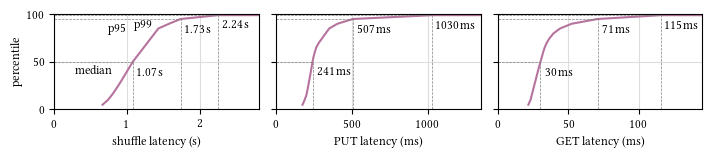

In [12]:
# Combined 3-axis CDF plot, each axis saved as a separate PDF.
fig, axes_arr = plt.subplots(
    nrows=1, ncols=3, sharex=False, sharey=True, figsize=figsize_wide_thin
)

# End-to-end shuffle latency
ax = axes_arr[0]
ax.plot(total_latency['value'], total_latency['percentile'])
for percentile in [50, 95, 99]:
    value = total_latency[total_latency['percentile'] == percentile]['value'].values[0]
    quantile = total_latency[total_latency['percentile'] == percentile]['percentile'].values[0]
    ax.vlines(x=value, ymin=0, ymax=quantile, colors='gray', linestyles='dashed', linewidth=0.5)
    ax.hlines(y=quantile, xmin=0, xmax=value, colors='gray', linestyles='dashed', linewidth=0.5)
    ax.annotate(
        'median' if percentile == 50 else f'p{percentile}',
        xy=(value / 2, quantile), xytext=(5 if percentile == 99 else 0, -7),
        textcoords='offset points', ha='center', va='center',
    )
    ax.annotate(
        f'{value:.2f}\,s', xy=(value, quantile), xytext=(3, -10), textcoords='offset points'
    )
ax.set_xlabel('shuffle latency (s)')
ax.set_ylabel('percentile')
ax.grid(axis='both', which='both', zorder=0)
ax.set_ylim(ymin=0, ymax=100)
ax.set_xlim(xmin=0.0, xmax=2.8)

# S3 PUT latency
ax = axes_arr[1]
ax.plot(s3_put_latency['value_ms'], s3_put_latency['percentile'])
for percentile in [50, 95, 99]:
    value = s3_put_latency[s3_put_latency['percentile'] == percentile]['value_ms'].values[0]
    quantile = s3_put_latency[s3_put_latency['percentile'] == percentile]['percentile'].values[0]
    ax.vlines(x=value, ymin=0, ymax=quantile, colors='gray', linestyles='dashed', linewidth=0.5)
    ax.hlines(y=quantile, xmin=0, xmax=value, colors='gray', linestyles='dashed', linewidth=0.5)
    ax.annotate(
        f'{value:.0f}\,ms', xy=(value, quantile), xytext=(3, -10), textcoords='offset points'
    )
ax.set_xlabel('PUT latency (ms)')
ax.grid(axis='both', which='both', zorder=0)
ax.set_ylim(ymin=0, ymax=100)
ax.set_xlim(xmin=0.0, xmax=1350)

# S3 GET latency
ax = axes_arr[2]
ax.plot(s3_get_latency['value_ms'], s3_get_latency['percentile'])
for percentile in [50, 95, 99]:
    value = s3_get_latency[s3_get_latency['percentile'] == percentile]['value_ms'].values[0]
    quantile = s3_get_latency[s3_get_latency['percentile'] == percentile]['percentile'].values[0]
    ax.vlines(x=value, ymin=0, ymax=quantile, colors='gray', linestyles='dashed', linewidth=0.5)
    ax.hlines(y=quantile, xmin=0, xmax=value, colors='gray', linestyles='dashed', linewidth=0.5)
    ax.annotate(
        f'{value:.0f}\,ms', xy=(value, quantile), xytext=(3, -10), textcoords='offset points'
    )
ax.set_xlabel('GET latency (ms)')
ax.grid(axis='both', which='both', zorder=0)
ax.set_ylim(ymin=0, ymax=100)
ax.set_xlim(xmin=0.0, xmax=145)

plt.tight_layout(pad=0.075, h_pad=0.5, w_pad=0.5)

# Save each subplot individually by extracting its tight bounding box
for fname, ax in zip(
    ['plots/latency/total_latency_cdf.pdf',
     'plots/latency/put_latency_cdf.pdf',
     'plots/latency/get_latency_cdf.pdf'],
    axes_arr,
):
    extent = ax.get_tightbbox(fig.canvas.get_renderer())
    extent = extent.transformed(fig.dpi_scale_trans.inverted())
    fig.savefig(fname, bbox_inches=extent.padded(0.02))

plt.show()


## Batch Size

**Experiment setup:** 12 r6in.xlarge nodes (24 pods), target batch sizes
1, 2, 4, 8, 16, 32, 64, 128 MiB, 3 repetitions.

The batch size controls how much data BlobShuffle accumulates before writing a
blob to S3. Larger batches:
- **reduce** S3 request frequency → lower S3 costs and GET/PUT overhead
- **increase** end-to-end shuffle latency (records wait longer in the buffer)

The section plots throughput (aggregate and per-node), p95 end-to-end latency,
S3 PUT/GET rates, GET/PUT ratio, actual batch size ratio, estimated S3 and EC2
costs, and a scatter of total cost vs. latency.

**Steady-state window:** `sec_start >= 360 s` (6-minute warm-up excluded).

**AWS pricing (us-east-1):** r6in.xlarge = \$0.34866/h, S3 PUT = \$0.005/1000,
S3 GET = \$0.0004/1000.

In [13]:
batchsize_12x2 = all_timeseries[
    (all_timeseries['dir'] == "results-01") &
    (all_timeseries['experiment_id'] == 16)
]


### Throughput


In [14]:
# Aggregate output throughput: mean per repetition, then median across repetitions
avg_out_throughput = (
    batchsize_12x2[
        (batchsize_12x2['metric'] == 'generic_output_throughput') &
        (batchsize_12x2['sec_start'] >= 360)
    ]
    .groupby(['load', 'resources', 'repetition', 'labels'])['value']
    .agg('mean').reset_index()
    .groupby(['load', 'resources'])['value']
    .agg(['median', 'min', 'max']).reset_index()
)
avg_out_throughput['batchsize'] = (avg_out_throughput['load'] / 1024 / 1024).astype(int)
avg_out_throughput['throughput_gbytesps_median'] = avg_out_throughput['median'] / 1024 / 1024
avg_out_throughput['throughput_gbytesps_min'] = avg_out_throughput['min'] / 1024 / 1024
avg_out_throughput['throughput_gbytesps_max'] = avg_out_throughput['max'] / 1024 / 1024
avg_out_throughput


,load,resources,median,min,max,batchsize,throughput_gbytesps_median,throughput_gbytesps_min,throughput_gbytesps_max
0,1048576,24,8.526110e+05,8.499465e+05,8.552138e+05,1,0.813113,0.810572,0.815595
1,2097152,24,1.086636e+06,1.073913e+06,1.088976e+06,2,1.036297,1.024164,1.038528
2,4194304,24,1.171307e+06,1.170285e+06,1.172251e+06,4,1.117045,1.116071,1.117946
3,8388608,24,1.310170e+06,1.305585e+06,1.317701e+06,8,1.249476,1.245103,1.256658
4,16777216,24,1.430100e+06,1.419505e+06,1.433013e+06,16,1.363850,1.353746,1.366628
5,33554432,24,1.501590e+06,1.476912e+06,1.503911e+06,32,1.432028,1.408493,1.434242
6,67108864,24,1.477029e+06,1.473511e+06,1.481098e+06,64,1.408605,1.405250,1.412485
7,134217728,24,1.294166e+06,1.285724e+06,1.295685e+06,128,1.234213,1.226162,1.235662


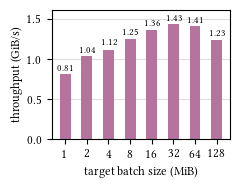

In [15]:
fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(avg_out_throughput['batchsize'].astype(str),
              avg_out_throughput['throughput_gbytesps_median'], width=0.5)
ax.bar_label(bars, padding=1, fmt='%.2f', fontsize=7)
ax.set_ylim(0, avg_out_throughput['throughput_gbytesps_median'].max() * 1.125)
ax.set_xlabel('target batch size (MiB)')
ax.set_ylabel('throughput (GiB/s)')
plt.tight_layout(pad=0.075)
plt.savefig('plots/batchsize/batchsize_throughput.pdf', dpi=300)
plt.show()


In [16]:
# Throughput per node: 2 pods per r6in.xlarge instance
avg_out_throughput_per_node = avg_out_throughput.copy()
avg_out_throughput_per_node['throughput_pod_mbytesps_median'] = (
    avg_out_throughput_per_node['throughput_gbytesps_median']
    / avg_out_throughput_per_node['resources'] * 1024
)
# 2 pods per instance
avg_out_throughput_per_node['throughput_inst_mbytesps_median'] = (
    avg_out_throughput_per_node['throughput_pod_mbytesps_median'] * 2
)
avg_out_throughput_per_node


,load,resources,median,min,max,batchsize,throughput_gbytesps_median,throughput_gbytesps_min,throughput_gbytesps_max,throughput_pod_mbytesps_median,throughput_inst_mbytesps_median
0,1048576,24,8.526110e+05,8.499465e+05,8.552138e+05,1,0.813113,0.810572,0.815595,34.692830,69.385661
1,2097152,24,1.086636e+06,1.073913e+06,1.088976e+06,2,1.036297,1.024164,1.038528,44.215320,88.430640
2,4194304,24,1.171307e+06,1.170285e+06,1.172251e+06,4,1.117045,1.116071,1.117946,47.660596,95.321192
3,8388608,24,1.310170e+06,1.305585e+06,1.317701e+06,8,1.249476,1.245103,1.256658,53.310958,106.621916
4,16777216,24,1.430100e+06,1.419505e+06,1.433013e+06,16,1.363850,1.353746,1.366628,58.190918,116.381836
5,33554432,24,1.501590e+06,1.476912e+06,1.503911e+06,32,1.432028,1.408493,1.434242,61.099865,122.199730
6,67108864,24,1.477029e+06,1.473511e+06,1.481098e+06,64,1.408605,1.405250,1.412485,60.100473,120.200946
7,134217728,24,1.294166e+06,1.285724e+06,1.295685e+06,128,1.234213,1.226162,1.235662,52.659752,105.319504


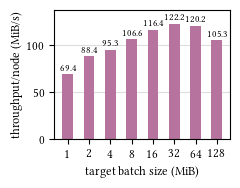

In [17]:
fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(
    avg_out_throughput_per_node['batchsize'].astype(str),
    avg_out_throughput_per_node['throughput_inst_mbytesps_median'], width=0.5
)
ax.bar_label(bars, padding=1, fmt='%.1f', fontsize=7)
ax.set_ylim(0, avg_out_throughput_per_node['throughput_inst_mbytesps_median'].max() * 1.125)
ax.set_xlabel('target batch size (MiB)')
ax.set_ylabel('throughput/node (MiB/s)')
plt.tight_layout(pad=0.075)
plt.savefig('plots/batchsize/batchsize_throughput_per_node.pdf', dpi=300)
plt.show()


### Latency


In [18]:
p95_latency = (
    batchsize_12x2[
        (batchsize_12x2['metric'] == 'generic_latency_p95_total') &
        (batchsize_12x2['sec_start'] >= 360)
    ]
    .sort_values('sec_start')
    .groupby(['load', 'resources', 'repetition', 'labels'])['value']
    .last().reset_index()
    .groupby(['load', 'resources'])['value']
    .agg(['median']).reset_index()
)
p95_latency['batchsize'] = (p95_latency['load'] / 1024 / 1024).astype(int)
p95_latency


,load,resources,median,batchsize
0,1048576,24,0.857216,1
1,2097152,24,0.841548,2
2,4194304,24,0.987730,4
3,8388608,24,1.339714,8
4,16777216,24,1.731062,16
5,33554432,24,2.714006,32
6,67108864,24,5.418385,64
7,134217728,24,10.334880,128


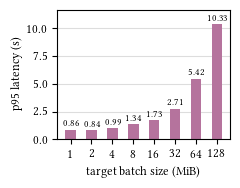

In [19]:
fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(p95_latency['batchsize'].astype(str), p95_latency['median'], width=0.5)
ax.bar_label(bars, padding=1, fmt='%.2f', fontsize=7)
ax.set_ylim(0, p95_latency['median'].max() * 1.125)
ax.set_xlabel('target batch size (MiB)')
ax.set_ylabel('p95 latency (s)')
plt.tight_layout(pad=0.075)
plt.savefig('plots/batchsize/batchsize_latency.pdf', dpi=300)
plt.show()


### S3 Requests


In [20]:
avg_put_requests = (
    batchsize_12x2[
        (batchsize_12x2['metric'] == 'generic_put_requests') &
        (batchsize_12x2['sec_start'] >= 360)
    ]
    .groupby(['load', 'resources', 'repetition', 'labels'])['value']
    .agg('mean').reset_index()
    .groupby(['load', 'resources'])['value']
    .agg(['median', 'min', 'max']).reset_index()
)
avg_put_requests['batchsize'] = (avg_put_requests['load'] / 1024 / 1024).astype(int)
avg_put_requests


,load,resources,median,min,max,batchsize
0,1048576,24,879.873751,877.171267,882.781589,1
1,2097152,24,556.754165,550.269206,557.882385,2
2,4194304,24,298.980817,298.747899,299.216304,4
3,8388608,24,167.135769,166.611970,168.087088,8
4,16777216,24,91.527500,90.893574,91.763349,16
5,33554432,24,48.579809,47.782579,48.721986,32
6,67108864,24,24.496318,24.417432,24.592681,64
7,134217728,24,11.264214,11.225667,11.306423,128


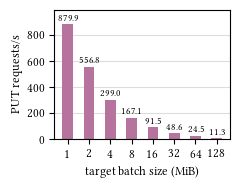

In [21]:
fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(avg_put_requests['batchsize'].astype(str), avg_put_requests['median'], width=0.5)
ax.bar_label(bars, padding=1, fmt='%.1f', fontsize=7)
ax.set_ylim(0, avg_put_requests['median'].max() * 1.125)
ax.set_xlabel('target batch size (MiB)')
ax.set_ylabel('PUT requests/s')
plt.tight_layout(pad=0.075)
plt.savefig('plots/batchsize/batchsize_puts.pdf', dpi=300)
plt.show()


In [22]:
avg_get_requests = (
    batchsize_12x2[
        (batchsize_12x2['metric'] == 'generic_get_requests') &
        (batchsize_12x2['sec_start'] >= 360)
    ]
    .groupby(['load', 'resources', 'repetition', 'labels'])['value']
    .agg('mean').reset_index()
    .groupby(['load', 'resources'])['value']
    .agg(['median', 'min', 'max']).reset_index()
)
avg_get_requests['batchsize'] = (avg_get_requests['load'] / 1024 / 1024).astype(int)
avg_get_requests


,load,resources,median,min,max,batchsize
0,1048576,24,586.737970,584.835430,588.465912,1
1,2097152,24,371.133034,366.849201,371.932835,2
2,4194304,24,199.356814,199.151443,199.519110,4
3,8388608,24,111.456877,111.079829,112.069728,8
4,16777216,24,61.019259,60.633024,61.176181,16
5,33554432,24,32.415579,31.855040,32.458695,32
6,67108864,24,16.330277,16.262840,16.388073,64
7,134217728,24,7.527523,7.471555,7.548637,128


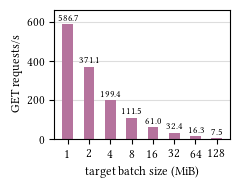

In [23]:
fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(avg_get_requests['batchsize'].astype(str), avg_get_requests['median'], width=0.5)
ax.bar_label(bars, padding=1, fmt='%.1f', fontsize=7)
ax.set_ylim(0, avg_get_requests['median'].max() * 1.125)
ax.set_xlabel('target batch size (MiB)')
ax.set_ylabel('GET requests/s')
plt.tight_layout(pad=0.075)
plt.savefig('plots/batchsize/batchsize_gets.pdf', dpi=300)
plt.show()


In [24]:
avg_gets_per_puts = avg_put_requests.merge(
    avg_get_requests, on=['load', 'resources', 'batchsize'], suffixes=('_put', '_get')
)
avg_gets_per_puts['gets_per_puts'] = (
    avg_gets_per_puts['median_get'] / avg_gets_per_puts['median_put']
)
avg_gets_per_puts[['batchsize', 'median_put', 'median_get', 'gets_per_puts']]


,batchsize,median_put,median_get,gets_per_puts
0,1,879.873751,586.737970,0.666843
1,2,556.754165,371.133034,0.666601
2,4,298.980817,199.356814,0.666788
3,8,167.135769,111.456877,0.666864
4,16,91.527500,61.019259,0.666677
5,32,48.579809,32.415579,0.667264
6,64,24.496318,16.330277,0.666642
7,128,11.264214,7.527523,0.668269


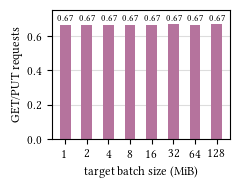

In [25]:
fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(avg_gets_per_puts['batchsize'].astype(str),
              avg_gets_per_puts['gets_per_puts'], width=0.5)
ax.bar_label(bars, padding=1, fmt='%.2f', fontsize=7)
ax.set_ylim(0, avg_gets_per_puts['gets_per_puts'].max() * 1.125)
ax.set_xlabel('target batch size (MiB)')
ax.set_ylabel('GET/PUT requests')
plt.tight_layout(pad=0.075)
plt.savefig('plots/batchsize/batchsize_gets_per_puts.pdf', dpi=300)
plt.show()


### Actual Batch Size


In [26]:
# Actual (measured) batch size vs. target batch size
# A ratio < 100% means the buffer was not fully filled before flushing
avg_batch_size = (
    batchsize_12x2[
        (batchsize_12x2['metric'] == 'generic_batch_size_bytes') &
        (batchsize_12x2['sec_start'] >= 360)
    ]
    .groupby(['load', 'resources', 'repetition', 'labels'])['value']
    .agg('mean').reset_index()
    .groupby(['load', 'resources'])['value']
    .agg(['median', 'min', 'max']).reset_index()
)
avg_batch_size['batchsize'] = (avg_batch_size['load'] / 1024 / 1024).astype(int)
avg_batch_size['median_mib'] = avg_batch_size['median'] / 1024 / 1024
avg_batch_size['ratio'] = avg_batch_size['median_mib'] / avg_batch_size['batchsize'] * 100
avg_batch_size


,load,resources,median,min,max,batchsize,median_mib,ratio
0,1048576,24,1.019369e+06,1.019288e+06,1.019378e+06,1,0.972146,97.214559
1,2097152,24,2.053433e+06,2.053065e+06,2.053561e+06,2,1.958306,97.915309
2,4194304,24,4.120997e+06,4.120805e+06,4.121575e+06,4,3.930089,98.252236
3,8388608,24,8.247517e+06,8.246651e+06,8.248965e+06,8,7.865445,98.318065
4,16777216,24,1.642895e+07,1.642771e+07,1.643314e+07,16,15.667872,97.924201
5,33554432,24,3.252311e+07,3.250361e+07,3.253711e+07,32,31.016454,96.926419
6,67108864,24,6.350025e+07,6.339713e+07,6.353273e+07,64,60.558556,94.622743
7,134217728,24,1.209090e+08,1.208669e+08,1.209808e+08,128,115.307795,90.084215


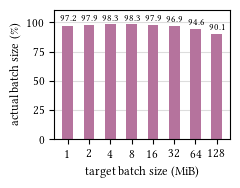

In [27]:
fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(avg_batch_size['batchsize'].astype(str), avg_batch_size['ratio'], width=0.5)
ax.bar_label(bars, padding=1, fmt='%.1f', fontsize=7)
ax.set_ylim(0, avg_batch_size['ratio'].max() * 1.125)
ax.set_xlabel('target batch size (MiB)')
ax.set_ylabel('actual batch size (\%)')
plt.tight_layout(pad=0.075)
plt.savefig('plots/batchsize/batchsize_actual_ratio.pdf', dpi=300)
plt.show()


### Costs


In [28]:
# AWS pricing constants (us-east-1)
costs_r6inxlarge = 0.34866      # USD/h per r6in.xlarge instance
costs_s3_put_per_1000 = 0.005   # USD per 1000 S3 PUT requests
costs_s3_get_per_1000 = 0.0004  # USD per 1000 S3 GET requests
costs_s3_gb_per_month = 0.023   # USD per GB-month of S3 storage 

s3_retention_time_hours = 1

# Merge all metrics into a single DataFrame for cost computation
batchsize_throughput = avg_batch_size.merge(
    avg_out_throughput, on='load', suffixes=('_batchsize', '_throughput')
)
all_metrics = batchsize_throughput.merge(
    p95_latency, on='load', suffixes=('', '_latency')
)
all_metrics['latency_median'] = all_metrics['median']
all_metrics.drop(columns=['median'], inplace=True)
all_metrics = all_metrics.merge(avg_put_requests, on='load', suffixes=('', '_puts'))
all_metrics['value_puts'] = all_metrics['median']
all_metrics.drop(columns=['median', 'min', 'max'], inplace=True)
all_metrics = all_metrics.merge(avg_get_requests, on='load', suffixes=('', '_gets'))
all_metrics['value_gets'] = all_metrics['median']
all_metrics.drop(columns=['median', 'min', 'max'], inplace=True)

# S3 costs per hour = request_rate/s * 3600 s/h * (price / 1000 requests)
all_metrics['costs_s3_put_hour'] = (
    (all_metrics['value_puts'] / 1000) * costs_s3_put_per_1000
) * 60 * 60
all_metrics['costs_s3_put_hour_gbps'] = (
    all_metrics['costs_s3_put_hour'] / all_metrics['throughput_gbytesps_median']
)
all_metrics['costs_s3_get_hour'] = (
    (all_metrics['value_gets'] / 1000) * costs_s3_get_per_1000
) * 60 * 60
all_metrics['costs_s3_get_hour_gbps'] = (
    all_metrics['costs_s3_get_hour'] / all_metrics['throughput_gbytesps_median']
)
all_metrics['costs_s3_req_hour'] = (
    all_metrics['costs_s3_put_hour'] + all_metrics['costs_s3_get_hour']
)
all_metrics['costs_s3_req_hour_gbps'] = (
    all_metrics['costs_s3_put_hour_gbps'] + all_metrics['costs_s3_get_hour_gbps']
)
all_metrics['costs_s3_retention_hour'] = (
    all_metrics['throughput_gbytesps_median']
    * 60 * 60 * s3_retention_time_hours 
    * (costs_s3_gb_per_month / 30 / 24)
)
all_metrics['costs_s3_retention_hour_gbps'] = (
    all_metrics['costs_s3_retention_hour'] / all_metrics['throughput_gbytesps_median']
)
all_metrics['costs_s3_hour'] = (
    all_metrics['costs_s3_put_hour'] + all_metrics['costs_s3_get_hour'] + all_metrics['costs_s3_retention_hour']
)

# EC2 costs: resources = number of pods, 2 pods per instance
all_metrics['costs_ec2_hour'] = (
    all_metrics['resources'] * costs_r6inxlarge
) / 2

# Normalized costs: divide by throughput in GiB/s (for fair comparison across sizes)
all_metrics['costs_s3_hour_gbps'] = (
    all_metrics['costs_s3_hour'] / all_metrics['throughput_gbytesps_median']
)
all_metrics['costs_ec2_hour_gbps'] = (
    all_metrics['costs_ec2_hour'] / all_metrics['throughput_gbytesps_median']
)
all_metrics['costs_hour_gbps'] = (
    all_metrics['costs_s3_hour_gbps'] + all_metrics['costs_ec2_hour_gbps']
)
all_metrics[['batchsize_batchsize', 'throughput_gbytesps_median',
              'costs_s3_hour', 'costs_ec2_hour_gbps', 'costs_hour_gbps',
              'latency_median']]


,batchsize_batchsize,throughput_gbytesps_median,costs_s3_hour,costs_ec2_hour_gbps,costs_hour_gbps,latency_median
0,1,0.813113,16.776138,5.145557,25.777540,0.857216
1,2,1.036297,10.675181,4.037377,14.338657,0.841548
2,4,1.117045,5.797189,3.745524,8.935277,0.987730
3,8,1.249476,3.312631,3.348541,5.999758,1.339714
4,16,1.363850,1.892205,3.067728,4.455129,1.731062
5,32,1.432028,1.085798,2.921675,3.679899,2.714006
6,64,1.408605,0.626439,2.970258,3.414981,5.418385
7,128,1.234213,0.355530,3.389950,3.678012,10.334880


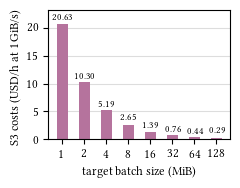

In [29]:
fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(all_metrics['batchsize_batchsize'].astype(str),
              all_metrics['costs_s3_hour_gbps'], width=0.5)
ax.bar_label(bars, padding=1, fmt='%.2f', fontsize=7)
ax.set_ylim(0, all_metrics['costs_s3_hour_gbps'].max() * 1.125)
ax.set_xlabel('target batch size (MiB)')
ax.set_ylabel('S3 costs (USD/h at 1\,GiB/s)', loc='top')
plt.tight_layout(pad=0.075)
plt.savefig('plots/batchsize/batchsize_s3costs.pdf', dpi=300)
plt.show()


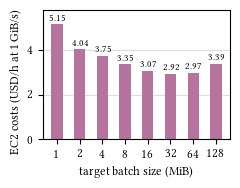

In [30]:
fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(all_metrics['batchsize_batchsize'].astype(str),
              all_metrics['costs_ec2_hour_gbps'], width=0.5)
ax.bar_label(bars, padding=1, fmt='%.2f', fontsize=7)
ax.set_ylim(0, all_metrics['costs_ec2_hour_gbps'].max() * 1.125)
ax.set_xlabel('target batch size (MiB)')
ax.set_ylabel('EC2 costs (USD/h at 1\,GiB/s)', loc='top')
plt.tight_layout(pad=0.075)
plt.savefig('plots/batchsize/batchsize_ec2costs.pdf', dpi=300)
plt.show()


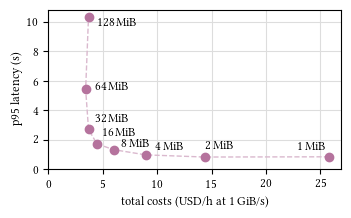

In [31]:
fig, ax = plt.subplots(figsize=figsize_single)
ax.scatter(all_metrics['costs_hour_gbps'], all_metrics['latency_median'], zorder=2)
ax.plot(
    all_metrics['costs_hour_gbps'], all_metrics['latency_median'],
    linestyle='--', zorder=1, color=lighten(palette[0], 0.5), linewidth=1,
)
for i, txt in enumerate(all_metrics['batchsize_batchsize']):
    x_offset = 7 if txt > 32 else 0
    y_offset = 5 if txt <= 16 else 0
    if txt == 1:   x_offset = -22
    if txt == 4:   x_offset, y_offset = 7, 4
    if txt == 8:   x_offset, y_offset = 5, 2
    if txt == 16:  x_offset, y_offset = 4, 6
    if txt == 32:  x_offset, y_offset = 5, 5
    if txt == 128: y_offset = -7
    ax.annotate(
        f"{txt}\,MiB",
        (all_metrics['costs_hour_gbps'].iloc[i], all_metrics['latency_median'].iloc[i]),
        xytext=(x_offset, y_offset), textcoords='offset points',
    )
ax.set_xlabel('total costs (USD/h at 1\,GiB/s)')
ax.set_ylabel('p95 latency (s)')
ax.grid(axis='both', which='both', zorder=0)
ax.set_ylim(ymin=0)
ax.set_xlim(xmin=0)
plt.tight_layout(pad=0.075)
plt.savefig('plots/batchsize/costs_latency.pdf', dpi=300)
plt.show()


In [32]:
# Cost comparison: BlobShuffle vs. direct Kafka replication
# Direct network transfer within AWS costs $0.01/GB per direction
print(
    f"Direct transfer (2x $0.01/GB): "
    f"${(2 * 0.01) * 3600:.2f} USD per hour per GiB/s"
)
print(
    f"Network costs with Kafka (3 replicas, 1 producer + 2 follower fetches): "
    f"${(2 * 0.01) * (2/3 + 2) * 3600:.2f} USD per hour per GiB/s"
)


Direct transfer (2x $0.01/GB): $72.00 USD per hour per GiB/s
Network costs with Kafka (3 replicas, 1 producer + 2 follower fetches): $192.00 USD per hour per GiB/s


## Partition Count

**Experiment setup:** 12 r6in.xlarge nodes (24 pods), 16 MiB target batch size,
varying number of Kafka topic partitions, 3 repetitions.

The number of Kafka partitions determines the parallelism of the repartitioning
and the granularity of the distributed cache. This section shows the effect on
aggregate output throughput, steady-state p95 end-to-end latency, and
distributed cache reads/s (hits + misses).

The partition count per run is derived from the `generic_num_partitions` metric
(filtered to the input topic label).

**Steady-state window:** `sec_start >= 360 s`.

In [33]:
partitions_eval = all_timeseries[
    (all_timeseries['dir'] == "results-02") &
    (all_timeseries['experiment_id'] >= 11) &
    (all_timeseries['experiment_id'] <= 16)
]


In [34]:
# Determine the actual partition count for each (load, resources, repetition)
# from the generic_num_partitions metric on the input topic
no_partitions = (
    partitions_eval[
        (partitions_eval['metric'] == 'generic_num_partitions') &
        (partitions_eval['sec_start'] >= 360)
    ]
    .groupby(['load', 'resources', 'repetition', 'labels', 'experiment_id'])['value']
    .agg('mean').reset_index()
)
no_partitions = no_partitions[no_partitions['labels'].str.contains('topic=input')]
no_partitions['partitions'] = no_partitions['value'].astype(int)
no_partitions = no_partitions.drop(columns=['labels', 'value'])
no_partitions.sort_values(
    by=['load', 'resources', 'repetition', 'partitions'], inplace=True
)
no_partitions


,load,resources,repetition,experiment_id,partitions
22,16777216,24,1,14,72
16,16777216,24,1,15,144
34,16777216,24,1,16,216
28,16777216,24,1,11,288
4,16777216,24,1,12,360
10,16777216,24,1,13,432
46,16777216,24,2,14,72
70,16777216,24,2,15,144
64,16777216,24,2,16,216
58,16777216,24,2,11,288


### Throughput



In [35]:

# Throughput: join with partition count, then aggregate
avg_out_throughput = (
    partitions_eval[
        (partitions_eval['metric'] == 'generic_output_throughput') &
        (partitions_eval['sec_start'] >= 360)
    ]
    .groupby(['load', 'resources', 'repetition', 'experiment_id', 'labels'])['value']
    .agg('mean').reset_index()
    .merge(no_partitions, on=['load', 'resources', 'repetition', 'experiment_id'])
    .groupby(['load', 'resources', 'partitions'])['value']
    .agg(['median']).reset_index()
)
avg_out_throughput['batchsize'] = (avg_out_throughput['load'] / 1024 / 1024).astype(int)
avg_out_throughput['throughput_gbytesps'] = avg_out_throughput['median'] / 1024 / 1024
avg_out_throughput['instances'] = avg_out_throughput['resources'] // 2
avg_out_throughput


,load,resources,partitions,median,batchsize,throughput_gbytesps,instances
0,16777216,24,72,1.401326e+06,16,1.336409,12
1,16777216,24,144,1.566492e+06,16,1.493923,12
2,16777216,24,216,1.462835e+06,16,1.395069,12
3,16777216,24,288,1.333387e+06,16,1.271617,12
4,16777216,24,360,1.251458e+06,16,1.193483,12
5,16777216,24,432,1.167908e+06,16,1.113804,12


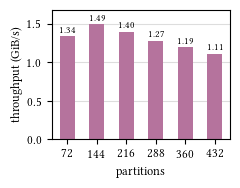

In [36]:
fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(avg_out_throughput['partitions'].astype(str),
              avg_out_throughput['throughput_gbytesps'], width=0.5)
ax.bar_label(bars, padding=1, fmt='%.2f', fontsize=7)
ax.set_ylim(0, avg_out_throughput['throughput_gbytesps'].max() * 1.125)
ax.set_xlabel('partitions')
ax.set_ylabel('throughput (GiB/s)')
plt.tight_layout(pad=0.075)
plt.savefig('plots/partitions/partitions_throughput.pdf', dpi=300)
plt.show()


### Latency



In [37]:
p95_latency = (
    partitions_eval[
        (partitions_eval['metric'] == 'generic_latency_p95_total') &
        (partitions_eval['sec_start'] >= 360)
    ]
    .sort_values('sec_start')
    .groupby(['load', 'resources', 'repetition', 'labels', 'experiment_id'])['value']
    .last().reset_index()
    .merge(no_partitions, on=['load', 'resources', 'repetition', 'experiment_id'])
    .groupby(['load', 'resources', 'partitions'])['value']
    .agg(['median']).reset_index()
)
p95_latency['batchsize'] = (p95_latency['load'] / 1024 / 1024).astype(int)
p95_latency['instances'] = p95_latency['resources'] // 2
p95_latency


,load,resources,partitions,median,batchsize,instances
0,16777216,24,72,1.637197,16,12
1,16777216,24,144,1.599382,16,12
2,16777216,24,216,1.753625,16,12
3,16777216,24,288,1.912255,16,12
4,16777216,24,360,2.079784,16,12
5,16777216,24,432,2.331472,16,12


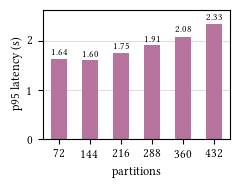

In [38]:
fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(p95_latency['partitions'].astype(str), p95_latency['median'], width=0.5)
ax.bar_label(bars, padding=1, fmt='%.2f', fontsize=7)
ax.set_ylim(0, p95_latency['median'].max() * 1.125)
ax.set_xlabel('partitions')
ax.set_ylabel('p95 latency (s)')
plt.tight_layout(pad=0.075)
plt.savefig('plots/partitions/partitions_latency.pdf', dpi=300)
plt.show()


### Cache Accesses


In [39]:
# Distributed cache reads = hits + misses
# The cache stores blobs written by other nodes to avoid redundant S3 GETs.
cache_hits = (
    partitions_eval[
        (partitions_eval['metric'] == 'generic_cache_distributed_hits') &
        (partitions_eval['sec_start'] >= 360)
    ]
    .groupby(['load', 'resources', 'repetition', 'labels', 'experiment_id'])['value']
    .agg('mean').reset_index()
    .merge(no_partitions, on=['load', 'resources', 'repetition', 'experiment_id'])
    .groupby(['load', 'resources', 'partitions'])['value']
    .agg(['median']).reset_index()
)
cache_misses = (
    partitions_eval[
        (partitions_eval['metric'] == 'generic_cache_distributed_misses') &
        (partitions_eval['sec_start'] >= 360)
    ]
    .groupby(['load', 'resources', 'repetition', 'labels', 'experiment_id'])['value']
    .agg('mean').reset_index()
    .merge(no_partitions, on=['load', 'resources', 'repetition', 'experiment_id'])
    .groupby(['load', 'resources', 'partitions'])['value']
    .agg(['median']).reset_index()
)
cache_accesses = cache_hits.merge(
    cache_misses, on=['load', 'resources', 'partitions'], suffixes=('_hits', '_misses')
)
cache_accesses['accesses'] = (
    cache_accesses['median_hits'] + cache_accesses['median_misses']
)
cache_accesses['instances'] = cache_accesses['resources'] // 2
cache_accesses['batchsize'] = (cache_accesses['load'] / 1024 / 1024).astype(int)
cache_accesses


,load,resources,partitions,median_hits,median_misses,accesses,instances,batchsize
0,16777216,24,72,2091.488336,59.755045,2151.243381,12,16
1,16777216,24,144,4738.133268,66.748648,4804.881916,12,16
2,16777216,24,216,6675.827023,62.377104,6738.204127,12,16
3,16777216,24,288,8133.719805,56.925687,8190.645493,12,16
4,16777216,24,360,9577.017860,53.536700,9630.554560,12,16
5,16777216,24,432,10738.024477,49.985326,10788.009803,12,16


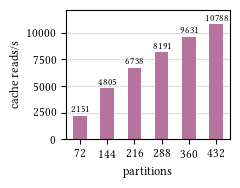

In [40]:
fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(cache_accesses['partitions'].astype(str),
              cache_accesses['accesses'], width=0.5)
ax.bar_label(bars, padding=1, fmt='%.0f', fontsize=7)
ax.set_ylim(0, cache_accesses['accesses'].max() * 1.125)
ax.set_xlabel('partitions')
ax.set_ylabel('cache reads/s')
plt.tight_layout(pad=0.075)
plt.savefig('plots/partitions/partitions_cache_accesses.pdf', dpi=300)
plt.show()


## Scalability

**Experiment setup:** 16 MiB target batch size, varying number of r6in.xlarge
nodes (3–24), 3 repetitions.

| exp id | nodes (instances) | pods |
|---|---|---|
| exp8 | 3 | 6 |
| exp9 | 6 | 12 |
| exp10 | 9 | 18 |
| exp4 | 12 | 24 |
| exp5 | 15 | 30 |
| exp6 | 18 | 36 |
| exp7 | 21 | 42 |
| exp3 | 24 | 48 |

This section evaluates whether BlobShuffle scales linearly with the number of
nodes, showing aggregate output throughput, throughput per node (expected to
remain roughly constant under linear scaling), and p95 end-to-end latency.

In [41]:
scalability = all_timeseries[
    (all_timeseries['dir'] == "results-02") &
    (all_timeseries['experiment_id'].isin([3, 4, 5, 6, 7, 8, 9, 10]))
]


### Throughput



In [42]:
avg_out_throughput = (
    scalability[
        (scalability['metric'] == 'generic_output_throughput') &
        (scalability['sec_start'] >= 360)
    ]
    .groupby(['load', 'resources', 'repetition', 'labels'])['value']
    .agg('mean').reset_index()
    .groupby(['load', 'resources'])['value']
    .agg(['median']).reset_index()
)
avg_out_throughput['batchsize'] = (avg_out_throughput['load'] / 1024 / 1024).astype(int)
avg_out_throughput['throughput_gbytesps'] = avg_out_throughput['median'] / 1024 / 1024
avg_out_throughput['instances'] = avg_out_throughput['resources'] // 2
avg_out_throughput['throughput_mbytesps_per_instance'] = (
    avg_out_throughput['throughput_gbytesps'] / avg_out_throughput['instances'] * 1024
)
avg_out_throughput.sort_values('instances', inplace=True)
avg_out_throughput


,load,resources,median,batchsize,throughput_gbytesps,instances,throughput_mbytesps_per_instance
0,16777216,6,3.907853e+05,16,0.372682,3,127.208771
1,16777216,12,8.858890e+05,16,0.844850,6,144.187663
2,16777216,18,1.155286e+06,16,1.101767,9,125.356570
3,16777216,24,1.550108e+06,16,1.478298,12,126.148126
4,16777216,30,1.854301e+06,16,1.768399,15,120.722733
5,16777216,36,1.959768e+06,16,1.868980,18,106.324201
6,16777216,42,2.364931e+06,16,2.255374,21,109.976345
7,16777216,48,2.507193e+06,16,2.391045,24,102.017935


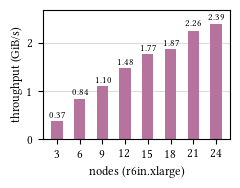

In [43]:
fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(avg_out_throughput['instances'].astype(str),
              avg_out_throughput['throughput_gbytesps'], width=0.5)
ax.bar_label(bars, padding=1, fmt='%.2f', fontsize=7)
ax.set_ylim(0, avg_out_throughput['throughput_gbytesps'].max() * 1.125)
ax.set_xlabel('nodes (r6in.xlarge)')
ax.set_ylabel('throughput (GiB/s)')
plt.tight_layout(pad=0.075)
plt.savefig('plots/scalability/instances_throughput.pdf', dpi=300)
plt.show()


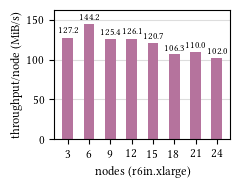

In [44]:
fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(avg_out_throughput['instances'].astype(str),
              avg_out_throughput['throughput_mbytesps_per_instance'], width=0.5)
ax.bar_label(bars, padding=1, fmt='%.1f', fontsize=7)
ax.set_ylim(0, avg_out_throughput['throughput_mbytesps_per_instance'].max() * 1.125)
ax.set_xlabel('nodes (r6in.xlarge)')
ax.set_ylabel('throughput/node (MiB/s)')
plt.tight_layout(pad=0.075)
plt.savefig('plots/scalability/instances_throughput-per-instance.pdf', dpi=300)
plt.show()


### Latency



In [45]:
p95_latency = (
    scalability[
        (scalability['metric'] == 'generic_latency_p95_total') &
        (scalability['sec_start'] >= 360)
    ]
    .sort_values('sec_start')
    .groupby(['load', 'resources', 'repetition', 'labels'])['value']
    .last().reset_index()
    .groupby(['load', 'resources'])['value']
    .agg(['median']).reset_index()
)
p95_latency['batchsize'] = (p95_latency['load'] / 1024 / 1024).astype(int)
p95_latency['instances'] = p95_latency['resources'] // 2
p95_latency.sort_values('instances', inplace=True)
p95_latency


,load,resources,median,batchsize,instances
0,16777216,6,1.778132,16,3
1,16777216,12,1.555546,16,6
2,16777216,18,1.612476,16,9
3,16777216,24,1.706759,16,12
4,16777216,30,1.697769,16,15
5,16777216,36,1.721600,16,18
6,16777216,42,1.702551,16,21
7,16777216,48,1.876496,16,24


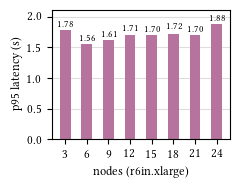

In [46]:

fig, ax = plt.subplots(figsize=figsize_3x)
bars = ax.bar(p95_latency['instances'].astype(str), p95_latency['median'], width=0.5)
ax.bar_label(bars, padding=1, fmt='%.2f', fontsize=7)
ax.set_ylim(0, p95_latency['median'].max() * 1.125)
ax.set_xlabel('nodes (r6in.xlarge)')
ax.set_ylabel('p95 latency (s)')
plt.tight_layout(pad=0.075)
plt.savefig('plots/scalability/instances_latency.pdf', dpi=300)
plt.show()
